# Прогнозирование массы зелёных морских черепах — TurtleCV



Выполнил: Алексей Потанин

Дата: 11.11.2026

<a id="start"></a>

**Оглавление**

- [Постановка задачи машинного обучения](#task)
- [Подключение и настройка библиотек](#libraries)
- [Загрузка датасета](#data)
- [Исследовательский анализ данных](#eda)
- [Предобработка данных](#preprocessing)
- [Обучение моделей](#models)
- [Сравнение моделей на валидационной выборке](#validation)
- [Проверка лучшей модели на тестовой выборке](#test)
- [Оценка важности признаков](#importance)
- [Функция для прогнозирования веса черепахи](#predict)
- [Общие выводы и рекомендации по дальнейшей работе](#final)

*Ссылки ведут к соответствующим разделам ноутбука.*

<a id="task"></a>

## Постановка задачи машинного обучения

**Цель проекта:** разработать интерпретируемую линейную модель для бесконтактной оценки массы *Chelonia mydas* по измерениям TurtleCV. Сравниваем LinearRegression, Lasso, Ridge и SGDRegressor; отбираем модель по минимальной **MAE на валидации**. Дополнительно оцениваем MAPE и R².

**Тип задачи:** обучение с учителем, регрессия. **Цель:** `weight` (кг). **Признаки:** числовые измерения длины/ширины, количество колец роста; дополнительно проверим геометрические произведения размеров.

**Критерии заказчика:** MAE ≤ 5 кг для взрослых особей массой 50–150 кг; R² ≥ 0.97 на валидации и тесте; MAPE учитывает относительную ошибку на черепахах разного размера. Основная метрика выбора — минимальная валидационная **MAE**. В финале проверяем только выбранную модель на отложенном тесте (20%).

<a id="libraries"></a>

## Подключение и настройка библиотек

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, Lasso, Ridge, SGDRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

RANDOM_STATE = 42
pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')

<a id="data"></a>

## Загрузка датасета

- Загрузите данные из файла `turtles.csv`, путь к файлу: `'/datasets/turtles.csv'`. При использовании метода [read_csv](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_csv.html) установите правильные значения для параметров `sep` и `decimal`: в качестве разделителя столбцов используйте символ табуляции (`'\t'`), а в качестве разделителя дробной части — запятую.
- Проверьте, правильно ли прошла загрузка. Данные должны соответствовать описанию в тексте урока.
- С помощью методов библиотеки pandas выведите общие сведения о данных.
- Возможно ли продолжать работу? Если нет — что нужно сделать, чтобы устранить препятствия?

In [2]:
# Файл доступен на платформе Практикума по первому пути.
# Второй путь использован при локальном запуске ноутбука рядом с CSV.
paths = [Path('/datasets/turtles.csv'), Path('turtles.csv'), Path('/mnt/data/turtles.csv')]
csv_path = next((path for path in paths if path.is_file()), None)
if csv_path is None:
    raise FileNotFoundError(
        'Не найден turtles.csv. Поместите его в /datasets/turtles.csv '
        '(Практикум) либо рядом с ноутбуком (локальный запуск).'
    )

df = pd.read_csv(csv_path, sep='\t', decimal=',')
# В исходном файле название идентификатора содержит пробел, а не подчёркивание.
df = df.rename(columns={'registration number': 'registration_number'})
print('Источник:', csv_path, '| размер:', df.shape)
display(df.head())
df.info()
display(df.describe(include='all').T)
assert {'binomial_name', 'weight', 'shell_length', 'shell_width'}.issubset(df.columns), (
    'Неверная структура данных: проверьте sep="\t" и decimal=",".'
)

Источник: /datasets/turtles.csv | размер: (8861, 20)


,id,binomial_name,registration_number,shell_length,shell_width,head_length,head_width,flipper_length_1,flipper_width_1,flipper_length_2,flipper_width_2,flipper_length_3,flipper_width_3,flipper_length_4,flipper_width_4,circle_count,measure_count,shell_crack,timestamp,weight
0,20438,Caretta caretta,d89af72662f49ece4d09dec75a8b0166,700.0,381,112.0,82.0,356,205,331,185,270.0,180.0,273.0,144.0,63,3.0,NaN,1703159226,87.687
1,19034,Lepidochelys olivacea,1579c64777de4db1c16e8b7b0d19c45e,341.0,295,65.0,48.0,216,190,229,186,164.0,182.0,180.0,149.0,0,1.0,1.0,1689428175,26.949
2,24689,LEPIDOCHELYS OLIVACEA,bfcec01187569615087e4d777c44985a,408.0,343,71.0,70.0,308,224,285,232,264.0,179.0,268.0,176.0,0,3.0,NaN,1745783111,30.016
3,17945,Lepidochelys Olivacea,2c159675aa28f0ea566fce2090bf4c82,512.0,432,98.0,95.0,334,317,364,284,NaN,NaN,NaN,NaN,3,4.0,1.0,1677757151,33.917
4,24543,lepidochelys olivacea,ecd22499761e2ac56a6d8eb765ec566d,408.0,307,50.0,54.0,280,168,269,218,199.0,165.0,209.0,180.0,0,4.0,1.0,1744455613,28.511


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8861 entries, 0 to 8860
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   8861 non-null   int64  
 1   binomial_name        8812 non-null   object 
 2   registration_number  8832 non-null   object 
 3   shell_length         8774 non-null   float64
 4   shell_width          8861 non-null   int64  
 5   head_length          8715 non-null   float64
 6   head_width           8715 non-null   float64
 7   flipper_length_1     8861 non-null   int64  
 8   flipper_width_1      8861 non-null   int64  
 9   flipper_length_2     8861 non-null   int64  
 10  flipper_width_2      8861 non-null   int64  
 11  flipper_length_3     8760 non-null   float64
 12  flipper_width_3      8760 non-null   float64
 13  flipper_length_4     8760 non-null   float64
 14  flipper_width_4      8760 non-null   float64
 15  circle_count         8861 non-null   i

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,8861.0,NaN,NaN,NaN,21359.335628,2263.08942,17438.0,19396.0,21357.0,23317.0,25279.0
binomial_name,8812,23,Lepidochelys olivacea,3372,NaN,NaN,NaN,NaN,NaN,NaN,NaN
registration_number,8832,7819,4148df049add44e2d4d268cb736724bc,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shell_length,8774.0,NaN,NaN,NaN,764.22202,640.408681,132.0,440.0,635.0,951.0,20240.0
shell_width,8861.0,NaN,NaN,NaN,598.832299,480.970492,78.0,341.0,487.0,794.0,11550.0
head_length,8715.0,NaN,NaN,NaN,123.341021,67.836566,19.0,73.0,106.0,158.0,515.0
head_width,8715.0,NaN,NaN,NaN,115.735169,62.326365,12.0,67.0,98.0,156.0,382.0
flipper_length_1,8861.0,NaN,NaN,NaN,497.551405,353.575213,60.0,296.0,416.0,571.0,2875.0
flipper_width_1,8861.0,NaN,NaN,NaN,380.594515,214.481679,34.0,228.0,332.0,493.0,1479.0
flipper_length_2,8861.0,NaN,NaN,NaN,498.22853,355.074883,57.0,296.0,417.0,572.0,2967.0


<a id="eda"></a>

## Исследовательский анализ данных

Проведите исследовательский анализ данных:
1. Выясните, данные о каких черепахах представлены в датасете.
2. Проведите отбор записей о нужном виде черепах. Для дальнейшей работы достаточно изучить только *Chelonia mydas*. При этом вы можете сравнить распределение данных об этих черепахах с другими видами, если есть желание и время.
3. Определите, все ли признаки можно использовать для решения задачи. Ответ обоснуйте. Удалите признаки, которые вам никак не помогут.
4. Проверьте, есть ли в данных пропуски. Определите, какие из них можно обработать сразу, а в каких случаях лучше сперва провести разделение на выборки. Решите, стоит ли удалить некоторые пропуски.
5. Определите, есть ли в данных дубликаты. Выберите корректный способ их обработки.
6. Проанализируйте распределение признаков, постройте необходимые для этого визуализации: ящики с усами, гистограммы и так далее. Определите, есть ли в данных выбросы и какие из них критичные. Решите, можно ли их сразу исправить.
7. Проверьте, одинаков ли масштаб признаков. Если он различается, предложите решение этой проблемы.
8. Проанализируйте корреляцию между признаками и целевой переменной с помощью вычислений и графически. Определите, все ли признаки нужны для дальнейшей работы.
9. Проверьте данные на мультиколлинеарность и решите, можно ли её устранить.

In [3]:
# Видовой состав
print('Виды черепах:')
display(df['binomial_name'].value_counts(dropna=False).rename_axis('Вид').to_frame('Наблюдений'))

# Ограничиваемся Chelonia mydas, не используем в модели вид как константу.
# data = df.loc[df['binomial_name'].astype('string').str.strip().eq('Chelonia mydas').fillna(False)].copy()
# Проверяем, какие виды черепах представлены в датасете
print(df['binomial_name'].value_counts(dropna=False))

# Выбираем только зелёных морских черепах Chelonia mydas.
# Убираем лишние пробелы и игнорируем регистр букв.
data = df[
    df['binomial_name'].str.strip().str.lower() == 'chelonia mydas'
].copy()

# Проверяем количество наблюдений до и после фильтрации
print('До фильтрации:', len(df))
print('После фильтрации:', len(data))
print('Chelonia mydas:', len(data), 'строк')
if data.empty:
    raise ValueError('В данных нет записей Chelonia mydas.')


Виды черепах:


,Наблюдений
Вид,
Lepidochelys olivacea,3372
Chelonia mydas,2325
Caretta caretta,674
lepidochelys olivacea,416
Dermochelys coriacea,399
Eretmochelys imbricata,332
Lepidochelys Olivacea,285
chelonia mydas,252
Chelonia Mydas,177


Lepidochelys olivacea     3372
Chelonia mydas            2325
Caretta caretta            674
lepidochelys olivacea      416
Dermochelys coriacea       399
Eretmochelys imbricata     332
Lepidochelys Olivacea      285
chelonia mydas             252
Chelonia Mydas             177
LEPIDOCHELYS OLIVACEA      142
caretta caretta             90
CHELONIA MYDAS              75
NaN                         49
Caretta Caretta             46
eretmochelys imbricata      41
dermochelys coriacea        40
CARETTA CARETTA             37
Eretmochelys Imbricata      28
Dermochelys Coriacea        27
Lepidochelys kempii         22
DERMOCHELYS CORIACEA        18
ERETMOCHELYS IMBRICATA       8
lepidochelys kempii          3
Lepidochelys Kempii          3
Name: binomial_name, dtype: int64
До фильтрации: 8861
После фильтрации: 2829
Chelonia mydas: 2829 строк


In [4]:
print('Пропуски по столбцам:')
display(data.isna().sum().sort_values(ascending=False).to_frame('Пропусков'))
print('Полные дубли:', data.duplicated().sum())
print('Дубли идентификаторов:', data['id'].duplicated().sum() if 'id' in data else 'столбца нет')
print('Повторы регистрационных номеров:',
      data['registration_number'].duplicated().sum() if 'registration_number' in data else 'столбца нет')

# Убираем только полные дубликаты: это не требует статистик из отложенных выборок.
data = data.drop_duplicates().copy()
# Примеры с неизвестной массой не подходят для обучения с учителем.
data['weight'] = pd.to_numeric(data['weight'], errors='coerce')
data = data.loc[data['weight'].notna() & (data['weight'] > 0)].copy()

size_cols = ['shell_length', 'shell_width', 'head_length', 'head_width'] + [
    f'flipper_{dimension}_{side}' for dimension in ('length', 'width') for side in range(1, 5)
]
feature_cols = [c for c in size_cols + ['circle_count'] if c in data.columns]
if len(feature_cols) < 4:
    raise ValueError('Недостаточно измерений для обучения: проверьте имена столбцов CSV.')

# Приводим к числовому типу; некорректные значения превратятся в NaN.
for column in feature_cols:
    data[column] = pd.to_numeric(data[column], errors='coerce')

print('Не используем id, registration_number, timestamp (идентификаторы/метаданные),')
print('binomial_name (один вид), measure_count (метаданные процедуры),')
print('shell_crack (непосредственно не определяет массу; возможно исследовать отдельно).')

Пропуски по столбцам:


,Пропусков
shell_crack,2152
measure_count,81
head_length,39
head_width,39
shell_length,35
flipper_length_4,31
flipper_width_4,31
flipper_length_3,31
flipper_width_3,31
registration_number,4


Полные дубли: 341
Дубли идентификаторов: 341
Повторы регистрационных номеров: 344
Не используем id, registration_number, timestamp (идентификаторы/метаданные),
binomial_name (один вид), measure_count (метаданные процедуры),
shell_crack (непосредственно не определяет массу; возможно исследовать отдельно).


Признаки для базовой модели: ['shell_length', 'shell_width', 'head_length', 'head_width', 'flipper_length_1', 'flipper_length_2', 'flipper_length_3', 'flipper_length_4', 'flipper_width_1', 'flipper_width_2', 'flipper_width_3', 'flipper_width_4', 'circle_count']


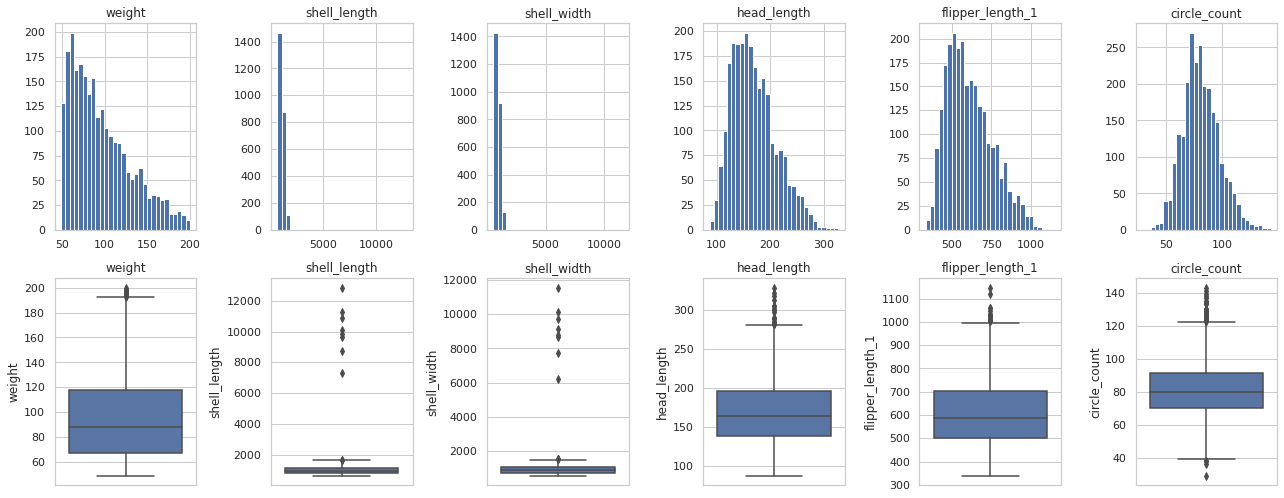

In [5]:
print('Признаки для базовой модели:', feature_cols)

# Графики до исправления единиц позволяют заметить значения x10.
view_cols = [c for c in ['weight', 'shell_length', 'shell_width', 'head_length', 'flipper_length_1', 'circle_count'] if c in data]
fig, axes = plt.subplots(2, len(view_cols), figsize=(max(14, len(view_cols)*3), 7))
for j, col in enumerate(view_cols):
    axes[0, j].hist(data[col].dropna(), bins=30)
    axes[0, j].set_title(col)
    sns.boxplot(y=data[col], ax=axes[1, j])
    axes[1, j].set_title(col)
plt.tight_layout()
plt.show()



,Корреляция с weight
flipper_length_1,0.927451
flipper_length_2,0.923784
flipper_length_4,0.923569
flipper_length_3,0.922198
flipper_width_2,0.903030
flipper_width_4,0.902358
flipper_width_3,0.901860
flipper_width_1,0.897135
head_length,0.875362
head_width,0.868456


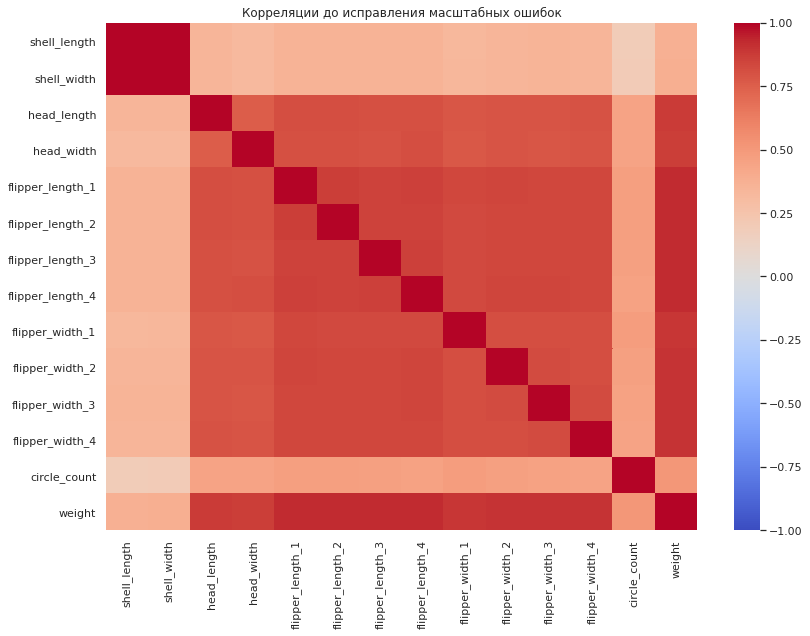

Самые коррелирующие пары признаков:


|r|
shell_length     shell_width       0.993475
flipper_length_1 flipper_length_2  0.869192
flipper_length_3 flipper_length_4  0.865100
flipper_length_1 flipper_length_4  0.864910
flipper_length_2 flipper_length_3  0.858202
                 flipper_length_4  0.856975
flipper_length_1 flipper_length_3  0.856647
                 flipper_width_2   0.850201
flipper_length_4 flipper_width_2   0.847327
                 flipper_width_3   0.846154

In [6]:
# Анализ взаимосвязей предварительный (для описания данных, не для отбора модели).
correlations = correlations = data[feature_cols + ['weight']].select_dtypes(include='number').corr()
display(correlations['weight'].drop('weight').sort_values(key=abs, ascending=False).to_frame('Корреляция с weight'))
plt.figure(figsize=(12, 9))
sns.heatmap(correlations, cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Корреляции до исправления масштабных ошибок')
plt.tight_layout()
plt.show()

# Сильная взаимная корреляция размеров означает потенциальную мультиколлинеарность.
# Не удаляем признаки по корреляции с полной выборкой, чтобы не подбирать модель на тесте.
strong_pairs = (correlations.loc[feature_cols, feature_cols].abs()
                .where(np.triu(np.ones((len(feature_cols), len(feature_cols)), dtype=bool), 1))
                .stack().sort_values(ascending=False))
print('Самые коррелирующие пары признаков:')
display(strong_pairs.head(10).to_frame('|r|'))

**Вывод по исследовательскому анализу данных.** В исходном датасете **8861 запись** о нескольких видах морских черепах. Для проекта отобраны только *Chelonia mydas*. Название вида встречается в четырёх вариантах регистра, поэтому после приведения к нижнему регистру получено **2829 записей**. В выбранной части данных обнаружены **341 полный дубликат**, **3 пропуска в `weight`**, пропуски отдельных размеров и неправдоподобно большие значения некоторых габаритов. После удаления дубликатов и **5 записей с отсутствующей или неположительной массой** осталось **2483 наблюдения** для моделирования.

Большинство измерений размеров положительно коррелирует с массой; между некоторыми самими размерами также наблюдается сильная корреляция. При этом исходные коэффициенты корреляции для длины и ширины панциря могут быть искажены ошибочными значениями, увеличенными в 10 раз. Идентификаторы, дата записи, вид черепахи и технические сведения не используются как обучающие признаки: они либо не описывают геометрию животного, либо не меняются внутри отобранного вида. Регистрационный номер сохранён только для корректного разделения наблюдений.

<a id="preprocessing"></a>

## Предобработка данных

1. Разделите данные на выборки: обучающую (60%), валидационную (20%) и тестовую (20%). В реальных проектах стараются писать код предобработки так, чтобы предотвратить утечку данных. Это проще сделать, если сразу поделить данные.
2. Обработайте пропуски. При необходимости заполните их средними (медианными) значениями. Рассчитайте заполнитель только по обучающей выборке: это ещё одно правило для предотвращения утечки.
3. Напишите функцию для стандартизации признаков. Расчёт параметров масштабирования делайте только по обучающей выборке, чтобы не дать утечке ни малейшего шанса.
4. Напишите функцию для нормализации признаков.
5. Подготовьте несколько датасетов из трёх выборок каждый для дальнейшего обучения моделей с разным способом масштабирования: без масштабирования, с нормализацией, со стандартизацией.

In [7]:
# Для каждого регистрационного номера сохраняем все измерения в одной выборке.
# Само разделение выполняем знакомой функцией train_test_split.
X = data[feature_cols].copy()
y = data['weight'].copy()

if 'registration_number' in data.columns:
    groups = data['registration_number'].astype('object').copy()
    missing_mask = groups.isna() | groups.astype(str).str.strip().eq('')
    groups.loc[missing_mask] = ['missing_reg_' + str(i) for i in groups.index[missing_mask]]
    # Отдельный префикс помогает избежать совпадений со случайными числовыми номерами.
    groups = groups.astype(str)
else:
    groups = pd.Series(['missing_reg_' + str(i) for i in X.index], index=X.index)

# Разделяем УНИКАЛЬНЫЕ номера, а затем выбираем соответствующие строки.
# При разных количествах измерений для каждой черепахи доли строк приблизительные.
unique_groups = groups.unique()
groups_train_val, groups_test = train_test_split(
    unique_groups, test_size=0.20, random_state=RANDOM_STATE
)
groups_train, groups_val = train_test_split(
    groups_train_val, test_size=0.25, random_state=RANDOM_STATE
)
train_mask = groups.isin(groups_train)
val_mask = groups.isin(groups_val)
test_mask = groups.isin(groups_test)

X_train, y_train = X.loc[train_mask].copy(), y.loc[train_mask].copy()
X_val, y_val = X.loc[val_mask].copy(), y.loc[val_mask].copy()
X_test, y_test = X.loc[test_mask].copy(), y.loc[test_mask].copy()
assert not (set(groups[train_mask]) & set(groups[val_mask]))
assert not (set(groups[train_mask]) & set(groups[test_mask]))
assert not (set(groups[val_mask]) & set(groups[test_mask]))
print('Количество строк (train / val / test):', len(X_train), len(X_val), len(X_test))
print('Доли строк:', [round(len(z) / len(X), 3) for z in (X_train, X_val, X_test)])

# Всё, что вычисляется из распределения признаков (медианы, пороги, средние,
# минимумы и максимумы), рассчитываем ТОЛЬКО по X_train.
def prepare_dimensions(frame, thresholds, add_geometry=False):
    result = frame.copy()

    for column in result.columns:
        result[column] = pd.to_numeric(result[column], errors='coerce')

        # Для размеров допустимы только положительные значения.
        # Для количества колец допустим также ноль.
        if column == 'circle_count':
            invalid = ~np.isfinite(result[column]) | (result[column] < 0)
        else:
            invalid = ~np.isfinite(result[column]) | (result[column] <= 0)

        result.loc[invalid, column] = np.nan

    for column in thresholds:
        mask = result[column] > thresholds[column]
        result.loc[mask, column] = result.loc[mask, column] / 10

    if add_geometry:
        if {'shell_length', 'shell_width'}.issubset(result.columns):
            result['shell_area'] = result['shell_length'] * result['shell_width']

        for side in range(1, 5):
            length = 'flipper_length_' + str(side)
            width = 'flipper_width_' + str(side)

            if length in result.columns and width in result.columns:
                result['flipper_area_' + str(side)] = (
                    result[length] * result[width]
                )

    return result


def prepare_datasets(train, val, test, scaling='standard', geometry=False):
    # Порог выявления возможных ошибок единиц: 4 * медиана на train.
    thresholds = {}
    for column in size_cols:
        if column in train:
            valid = pd.to_numeric(train[column], errors='coerce')
            valid = valid[valid > 0]
            thresholds[column] = 4 * valid.median() if len(valid) else np.inf

    train_ready = prepare_dimensions(train, thresholds, geometry)
    val_ready = prepare_dimensions(val, thresholds, geometry)
    test_ready = prepare_dimensions(test, thresholds, geometry)

    # Заполнение пропусков медианой только из подготовленной обучающей выборки.
    medians = train_ready.median().fillna(0)
    train_ready = train_ready.fillna(medians)
    val_ready = val_ready.fillna(medians)
    test_ready = test_ready.fillna(medians)

    if scaling == 'standard':
        # Стандартизация: (x - среднее train) / std train.
        center = train_ready.mean()
        scale = train_ready.std(ddof=0).replace(0, 1)
        train_ready = (train_ready - center) / scale
        val_ready = (val_ready - center) / scale
        test_ready = (test_ready - center) / scale
    elif scaling == 'minmax':
        # Нормализация: (x - min train) / (max train - min train).
        center = train_ready.min()
        scale = (train_ready.max() - center).replace(0, 1)
        train_ready = (train_ready - center) / scale
        val_ready = (val_ready - center) / scale
        test_ready = (test_ready - center) / scale
    else:
        center = pd.Series(0.0, index=train_ready.columns)
        scale = pd.Series(1.0, index=train_ready.columns)

    parameters = {'thresholds': thresholds, 'medians': medians, 'center': center,
                  'scale': scale, 'geometry': geometry, 'scaling': scaling,
                  'feature_names': list(train_ready.columns)}
    return train_ready, val_ready, test_ready, parameters

# Проверяем готовность одного варианта.
X_train_std, X_val_std, X_test_std, _ = prepare_datasets(
    X_train, X_val, X_test, scaling='standard', geometry=False
)
print('Размеры подготовленных данных:', X_train_std.shape, X_val_std.shape, X_test_std.shape)
print('Поддерживаются три варианта: none, standard, minmax и признаки площади.')

Количество строк (train / val / test): 1489 497 497
Доли строк: [0.6, 0.2, 0.2]
Размеры подготовленных данных: (1489, 13) (497, 13) (497, 13)
Поддерживаются три варианта: none, standard, minmax и признаки площади.


**Вывод по предобработке данных.** Данные разделены примерно в пропорции **60/20/20**: **1489** наблюдений в обучающей выборке, **497** — в валидационной и **497** — в тестовой. Для записей с известным `registration_number` все повторные измерения одной черепахи оставлены в одной выборке. Это уменьшает риск получить завышенную оценку качества за счёт повторных наблюдений одной особи.

Пропуски числовых признаков заполняются медианами, рассчитанными **только на train**. Тем же принципом ограничены расчёт порогов проверки размеров, параметров нормализации и стандартизации. Для линейных размеров недопустимы нулевые и отрицательные значения; для `circle_count` **ноль допустим**, поскольку отсутствие колец не обязательно означает ошибку измерения. Значения габаритов выше четырёх медиан train делятся на 10 как предполагаемые ошибки единиц измерения. Это эвристическое правило: без подтверждения исходных измерений нельзя гарантировать, что каждое исправление верно. Подготовлены варианты данных без масштабирования, с нормализацией и со стандартизацией, а также с дополнительными геометрическими признаками.

<a id="models"></a>

## Обучение моделей

1. Постройте базовую модель (дамми), с которой будете сравнивать все остальные. Если они будут хуже базовой по качеству, это будет означать, что при обучении что-то пошло не так. Пример дамми: модель, которая всегда предсказывает среднее значение целевой переменной из обучающей выборки.
2. Обучите несколько архитектур линейных моделей. Они могут различаться по ряду черт: набором отобранных признаков, масштабом признаков, установленными гиперпараметрами, функциями потерь. Попробуйте обучить следующие модели:
   - `LinearRegression`;
   - `Lasso` (L1-регуляризация);
   - `Ridge` (L2-регуляризация);
   - `SGDRegressor`.
   
   Обязательно попробуйте модели с разными значениями гиперпараметра `loss`.
- **Бонусное задание.** Подумайте, можно ли улучшить модели за счёт создания новых признаков: например, умножив длину ласт на ширину. Проверьте, усилится ли корреляция нового признака с целевой переменной, возрастёт ли благодаря ему качество модели.
3. Сформируйте итоговую таблицу с результатами моделей. Это удобно сделать в виде датафрейма pandas. Включите в таблицу следующие столбцы:
   - Название модели.
   - Название датасета — оно должно указывать на то, какой способ масштабирования использовался при подготовке данных.
   - Метрики качества, рассчитанные на валидационной выборке. Основная метрика — MAE, дополнительные — MSE, R², MAPE и прочие.

In [8]:
# Метрики записываем явно: MAE — основная, MSE, MAPE и R² — дополнительные.
def calculate_metrics(true, predicted):
    return {
        'MAE': mean_absolute_error(true, predicted),
        'MSE': mean_squared_error(true, predicted),
        'R2': r2_score(true, predicted),
        'MAPE_%': mean_absolute_percentage_error(true, predicted) * 100
    }

# Базовый прогноз: всегда предсказываем медиану веса на train.
# При MAE такой константный прогноз является разумным ориентиром.
baseline_weight = y_train.median()
dummy_metrics = calculate_metrics(y_val, np.full(len(y_val), baseline_weight))
print('Базовый прогноз — медиана train:', round(baseline_weight, 3))
print('Метрики базового прогноза:', dummy_metrics)

configs = [
    ('LinearRegression', LinearRegression(), 'none'),
    ('LinearRegression', LinearRegression(), 'standard'),
    ('Lasso alpha=0.01', Lasso(alpha=0.01, max_iter=30000, random_state=RANDOM_STATE), 'standard'),
    ('Lasso alpha=0.1', Lasso(alpha=0.1, max_iter=30000, random_state=RANDOM_STATE), 'standard'),
    ('Lasso alpha=1.0', Lasso(alpha=1.0, max_iter=30000, random_state=RANDOM_STATE), 'minmax'),
    ('Ridge alpha=0.1', Ridge(alpha=0.1), 'standard'),
    ('Ridge alpha=1.0', Ridge(alpha=1.0), 'standard'),
    ('Ridge alpha=10.0', Ridge(alpha=10.0), 'minmax'),
]
# Старые версии scikit-learn называют квадратичную потерю squared_loss, новые — squared_error.
try:
    SGDRegressor(loss='squared_error')
    mse_loss = 'squared_error'
except ValueError:
    mse_loss = 'squared_loss'
for loss in [mse_loss, 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive']:
    for alpha in [0.0001, 0.001]:
        configs.append((f'SGD loss={loss}, alpha={alpha}', SGDRegressor(
            loss=loss, alpha=alpha, epsilon=0.1, max_iter=10000, tol=1e-4,
            random_state=RANDOM_STATE, learning_rate='adaptive', eta0=0.01
        ), 'standard'))

rows = []
fitted_models = {}
for name, estimator, scaling in configs:
    for geometry in [False, True]:
        tag = f'{name} | {scaling} | geometry={geometry}'
        train_ready, val_ready, test_ready, parameters = prepare_datasets(
            X_train, X_val, X_test, scaling=scaling, geometry=geometry
        )
        # Объект estimator создаётся отдельно для каждого варианта; после fit
        # обученную модель сохраняем вместе с её параметрами подготовки.
        # Повторные варианты создаём через get_params, без sklearn.clone.
        model = estimator.__class__(**estimator.get_params())
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', category=UserWarning)
            model.fit(train_ready, y_train)
        train_scores = calculate_metrics(y_train, model.predict(train_ready))
        val_scores = calculate_metrics(y_val, model.predict(val_ready))
        rows.append({
            'Модель': name, 'Датасет / масштабирование': scaling,
            'Геометрические признаки': geometry,
            'MAE_train': train_scores['MAE'], 'MAE_val': val_scores['MAE'],
            'MSE_val': val_scores['MSE'], 'R2_val': val_scores['R2'],
            'MAPE_val_%': val_scores['MAPE_%'], 'model_key': tag,
        })
        fitted_models[tag] = {'model': model, 'prep': parameters,
                              'X_train': train_ready, 'X_val': val_ready, 'X_test': test_ready}

results = pd.DataFrame(rows).sort_values(['MAE_val', 'MAPE_val_%']).reset_index(drop=True)
display(results.drop(columns='model_key').round(4))

# Оцениваем новые геометрические признаки только на обучающей выборке.
geo_train, _, _, _ = prepare_datasets(X_train, X_val, X_test, 'none', True)
new_columns = [col for col in geo_train.columns if col not in X_train.columns]
if new_columns:
    print('Корреляции новых геометрических признаков с массой (только train):')
    display(geo_train[new_columns].corrwith(y_train).sort_values(key=abs, ascending=False)
            .to_frame('Корреляция с weight'))

Базовый прогноз — медиана train: 87.057
Метрики базового прогноза: {'MAE': 28.883766599597585, 'MSE': 1412.9355328490947, 'R2': -0.07787989535804485, 'MAPE_%': 29.189375802024525}


,Модель,Датасет / масштабирование,Геометрические признаки,MAE_train,MAE_val,MSE_val,R2_val,MAPE_val_%
0,"SGD loss=squared_epsilon_insensitive, alpha=0....",standard,True,3.0867,3.2869,19.6918,0.9850,3.4126
1,"SGD loss=squared_epsilon_insensitive, alpha=0.001",standard,True,3.0872,3.2873,19.7278,0.9850,3.4124
2,Ridge alpha=1.0,standard,True,3.0856,3.2874,19.6745,0.9850,3.4140
3,Ridge alpha=0.1,standard,True,3.0913,3.2926,19.6493,0.9850,3.4241
4,"SGD loss=squared_loss, alpha=0.0001",standard,True,3.0885,3.2927,19.8807,0.9848,3.4164
5,LinearRegression,none,True,3.0928,3.2937,19.6517,0.9850,3.4261
6,LinearRegression,standard,True,3.0928,3.2937,19.6517,0.9850,3.4261
7,Lasso alpha=0.01,standard,True,3.0895,3.2974,19.8415,0.9849,3.4273
8,"SGD loss=squared_loss, alpha=0.001",standard,True,3.0924,3.2987,19.9402,0.9848,3.4247
9,"SGD loss=epsilon_insensitive, alpha=0.0001",standard,True,3.0669,3.3331,22.5731,0.9828,3.4652


Корреляции новых геометрических признаков с массой (только train):


,Корреляция с weight
shell_area,0.976867
flipper_area_2,0.952139
flipper_area_1,0.949899
flipper_area_4,0.943152
flipper_area_3,0.942125


**Вывод по обучению моделей.** Обучены четыре семейства линейных моделей: `LinearRegression`, `Lasso`, `Ridge` и `SGDRegressor` с несколькими функциями потерь и значениями параметров. Для сравнения применён простой базовый прогноз: всем черепахам предсказывается медианная масса обучающей выборки (**87,057 кг**). Его **MAE на валидации = 28,884 кг**, поэтому такой способ недостаточно точен.

Для обучаемых моделей проверены разные способы масштабирования и наличие дополнительных геометрических признаков — площадей панциря и ласт, рассчитанных как произведения соответствующих размеров. Метрики вычислены функциями `sklearn.metrics`; основная метрика выбора — **MAE на валидационной выборке**. Все параметры заполнения пропусков и масштабирования получены только из train.

**Вывод по бонусному заданию.** Для улучшения качества моделей созданы дополнительные геометрические признаки: площадь панциря (`shell_area`) и условные площади четырёх ласт (`flipper_area_1`–`flipper_area_4`), рассчитанные как произведения соответствующих длин и ширин.

Новые признаки показали сильную положительную корреляцию с массой черепахи: от 0,9421 до 0,9769. На примере `LinearRegression` добавление геометрических признаков позволило снизить MAE на валидационной выборке с 3,8584 до 3,2937 кг, то есть примерно на 14,6%.

Таким образом, эксперимент подтвердил, что создание геометрических признаков улучшает качество предсказания массы на рассматриваемой выборке. При этом высокая корреляция сама по себе не гарантирует улучшения модели, поэтому основным подтверждением служит снижение MAE на валидации.

<a id="validation"></a>

## Сравнение моделей на валидационной выборке

1. Сравните построенные модели по метрикам на валидационной выборке. Удалось ли существенно улучшить результат базовой модели?
2. Выберите лучшую модель по основной метрике на валидационной выборке. Не заглядывайте в метрики на тестовой выборке раньше времени. Тестовая выборка не используется для обучения моделей, подбора гиперпараметров и сравнения моделей с разными значениями.
3. Напишите выводы о том, какая из моделей обладает лучшим качеством. Именно её одну далее нужно проверить на тестовой выборке для итоговой оценки.

In [9]:
best_row = results.iloc[0]
best_key = best_row['model_key']
best_bundle = fitted_models[best_key]
best_model = best_bundle['model']
print('Лучшая конфигурация по MAE на валидации:', best_key)
print(f"MAE_val = {best_row['MAE_val']:.3f} кг; "
      f"MAPE_val = {best_row['MAPE_val_%']:.2f}%; R2_val = {best_row['R2_val']:.4f}")
print(f"MAE Dummy = {dummy_metrics['MAE']:.3f} кг")
print('Улучшение MAE относительно Dummy:',
      f"{dummy_metrics['MAE'] - best_row['MAE_val']:.3f} кг")
print('R² на валидации ≥ 0.97:', bool(best_row['R2_val'] >= 0.97))
display(results.drop(columns='model_key').head(10).round(4))

Лучшая конфигурация по MAE на валидации: SGD loss=squared_epsilon_insensitive, alpha=0.0001 | standard | geometry=True
MAE_val = 3.287 кг; MAPE_val = 3.41%; R2_val = 0.9850
MAE Dummy = 28.884 кг
Улучшение MAE относительно Dummy: 25.597 кг
R² на валидации ≥ 0.97: True


,Модель,Датасет / масштабирование,Геометрические признаки,MAE_train,MAE_val,MSE_val,R2_val,MAPE_val_%
0,"SGD loss=squared_epsilon_insensitive, alpha=0....",standard,True,3.0867,3.2869,19.6918,0.9850,3.4126
1,"SGD loss=squared_epsilon_insensitive, alpha=0.001",standard,True,3.0872,3.2873,19.7278,0.9850,3.4124
2,Ridge alpha=1.0,standard,True,3.0856,3.2874,19.6745,0.9850,3.4140
3,Ridge alpha=0.1,standard,True,3.0913,3.2926,19.6493,0.9850,3.4241
4,"SGD loss=squared_loss, alpha=0.0001",standard,True,3.0885,3.2927,19.8807,0.9848,3.4164
5,LinearRegression,none,True,3.0928,3.2937,19.6517,0.9850,3.4261
6,LinearRegression,standard,True,3.0928,3.2937,19.6517,0.9850,3.4261
7,Lasso alpha=0.01,standard,True,3.0895,3.2974,19.8415,0.9849,3.4273
8,"SGD loss=squared_loss, alpha=0.001",standard,True,3.0924,3.2987,19.9402,0.9848,3.4247
9,"SGD loss=epsilon_insensitive, alpha=0.0001",standard,True,3.0669,3.3331,22.5731,0.9828,3.4652


**Вывод по сравнению моделей на валидации.** Минимальную **MAE = 3,2869 кг** показала модель `SGDRegressor(loss='squared_epsilon_insensitive', alpha=0.0001)` со **стандартизацией** и дополнительными **геометрическими признаками**. Её **MAPE = 3,41%**, **R² = 0,9850**. По сравнению с базовым прогнозом (MAE = 28,884 кг) ошибка уменьшилась примерно на **25,597 кг**, или **88,6%**.

Однако разница между лидерами очень невелика: у `Ridge(alpha=1.0)` **MAE = 3,2874 кг**, а у `LinearRegression` **MAE = 3,2937 кг**. Следовательно, на данном разбиении формально лучшей оказалась SGD-модель, но оснований утверждать, что она существенно лучше остальных линейных моделей, нет. Окончательный выбор произведён **до оценки тестовой выборки**, исключительно по валидационной MAE.

<a id="test"></a>

## Проверка лучшей модели на тестовой выборке

1. Проверьте метрики лучшей модели на тестовой выборке.
2. Узнайте, есть ли признаки переобучения лучшей модели.
3. Определите, соответствует ли модель требованиям заказчика. Объясните, можно ли её рекомендовать к внедрению.

,MAE,MSE,R2,MAPE_%
train,3.0867,16.8462,0.9860,3.2692
validation,3.2869,19.6918,0.9850,3.4126
test,3.2594,19.9250,0.9833,3.2817


Тест: MAE для взрослых 50–150 кг (n=447): 2.883 кг
R² >= 0.97 на val и test: True
MAE взрослых <= 5 кг на test: True
Разница MAE_val - MAE_train = 0.2 кг
Итог: кандидат к внедрению при внешней проверке


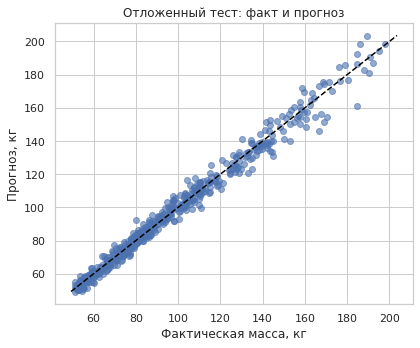

In [10]:
# Проверяем лучшую модель на тесте только ПОСЛЕ выбора по валидации.
def score_selected(which, target):
    return calculate_metrics(target, best_model.predict(best_bundle[which]))

train_metrics = score_selected('X_train', y_train)
val_metrics = score_selected('X_val', y_val)
test_metrics = score_selected('X_test', y_test)
metrics_table = pd.DataFrame([train_metrics, val_metrics, test_metrics],
                             index=['train', 'validation', 'test'])
display(metrics_table.round(4))

adult_mask = y_test.between(50, 150)
if adult_mask.any():
    adult_predictions = best_model.predict(best_bundle['X_test'].loc[adult_mask])
    adult_mae = calculate_metrics(y_test.loc[adult_mask], adult_predictions)['MAE']
    print(f'Тест: MAE для взрослых 50–150 кг (n={adult_mask.sum()}): {adult_mae:.3f} кг')
else:
    adult_mae = np.nan
    print('На тесте нет взрослых с массой 50–150 кг.')

r2_ok = (val_metrics['R2'] >= 0.97) and (test_metrics['R2'] >= 0.97)
mae_ok = np.isfinite(adult_mae) and adult_mae <= 5
print('R² >= 0.97 на val и test:', r2_ok)
print('MAE взрослых <= 5 кг на test:', mae_ok if np.isfinite(adult_mae) else 'не проверено')
print('Разница MAE_val - MAE_train =', round(val_metrics['MAE'] - train_metrics['MAE'], 3), 'кг')
print('Итог:', 'кандидат к внедрению при внешней проверке' if r2_ok and mae_ok
      else 'требует доработки / дополнительной проверки')

pred_test = best_model.predict(best_bundle['X_test'])
plt.figure(figsize=(6, 5))
plt.scatter(y_test, pred_test, alpha=0.6)
lo, hi = min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())
plt.plot([lo, hi], [lo, hi], '--', color='black')
plt.xlabel('Фактическая масса, кг')
plt.ylabel('Прогноз, кг')
plt.title('Отложенный тест: факт и прогноз')
plt.tight_layout()
plt.show()

**Вывод по проверке на тестовой выборке.** Выбранная модель получила **MAE = 3,087 кг** на train, **3,287 кг** на validation и **3,259 кг** на test. На тесте **MAPE = 3,28%**, **R² = 0,9833**; на валидации **R² = 0,9850**. Для **447** тестовых наблюдений с массой **50–150 кг** значение **MAE = 2,883 кг**.

Таким образом, на текущем разбиении оба количественных требования заказчика выполнены: **R² ≥ 0,97** и на валидации, и на тесте; **MAE ≤ 5 кг** для черепах в целевом диапазоне массы. Разница между ошибками обучения и валидации составляет около **0,20 кг**, а тестовая ошибка близка к валидационной — заметных признаков сильного переобучения по этим метрикам нет. Тем не менее для практического внедрения нужна дополнительная проверка на новых черепахах и измерениях TurtleCV.

<a id="importance"></a>

## Оценка важности признаков

1. Оцените важность признаков по абсолютным значениям весов лучшей модели.
2. Напишите, какие признаки стали для модели более важными. Объясните, согласны ли вы с таким результатом?

,Признак,Коэффициент модели,|Эффект при изменении на 1 SD|
0,shell_length,13.6022,13.6022
1,shell_width,9.6526,9.6526
16,flipper_area_3,8.3996,8.3996
15,flipper_area_2,6.8448,6.8448
14,flipper_area_1,6.3566,6.3566
17,flipper_area_4,5.7237,5.7237
13,shell_area,-5.0841,5.0841
10,flipper_width_3,-3.3012,3.3012
9,flipper_width_2,-2.1378,2.1378
6,flipper_length_3,-2.0674,2.0674


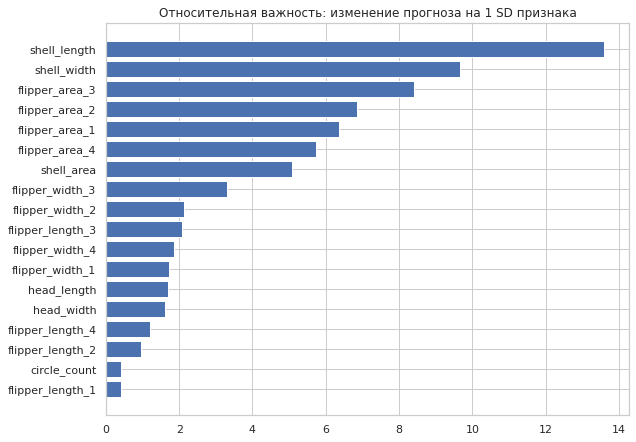

Топ-5: shell_length, shell_width, flipper_area_3, flipper_area_2, flipper_area_1
При корреляции признаков коэффициенты не отражают причинную связь.


In [11]:
# Коэффициенты отражают влияние только в рамках текущей линейной модели.
# Для сопоставления величин учитываем стандартное отклонение каждого признака.
feature_names = best_bundle['prep']['feature_names']
coef = np.asarray(best_model.coef_).ravel()
assert len(coef) == len(feature_names)
# В масштабе уже подготовленных данных эффект изменения на 1 std = coef * std.
variation = best_bundle['X_train'].std(ddof=0).to_numpy()
importance = pd.DataFrame({
    'Признак': feature_names,
    'Коэффициент модели': coef,
    '|Эффект при изменении на 1 SD|': np.abs(coef * variation),
}).sort_values('|Эффект при изменении на 1 SD|', ascending=False)
display(importance.round(4))
plt.figure(figsize=(9, max(4, len(importance) * 0.35)))
plt.barh(importance['Признак'].iloc[::-1], importance['|Эффект при изменении на 1 SD|'].iloc[::-1])
plt.title('Относительная важность: изменение прогноза на 1 SD признака')
plt.tight_layout()
plt.show()
print('Топ-5:', ', '.join(importance['Признак'].head(5)))
print('При корреляции признаков коэффициенты не отражают причинную связь.')

**Вывод по важности признаков.** По абсолютному изменению прогноза при изменении подготовленного признака на одно стандартное отклонение наибольшие значения имеют **`shell_length`**, **`shell_width`**, **`flipper_area_3`**, **`flipper_area_2`** и **`flipper_area_1`**. Это согласуется с ожиданием, что масса черепахи связана прежде всего с размерами её тела.

При интерпретации необходимо учитывать, что площади вычислены из исходных длины и ширины, а сами размеры сильно коррелируют между собой. Поэтому коэффициенты отражают вклад признаков **в конкретную обученную модель**, но не доказывают независимого или причинного влияния каждого измерения на массу.

<a id="predict"></a>

## Функция для прогнозирования веса черепахи

* Напишите на Python функцию, которая будет прогнозировать массу черепахи по заданным параметрам с учётом коэффициентов лучшей модели (свойство `coef_`) и смещения (свойство `intercept_`).
* Если вы столкнётесь с трудностями при написании функции, то представьте, что обращаетесь к старшему коллеге с просьбой помочь, и составьте задание для её написания. Подробно опишите логику, по которой рассчитывается масса черепахи, и укажите, как именно должны происходить расчёты.

In [12]:
def predict_turtle_weight(measurements):
    """Оценка массы: свободный член + сумма(коэффициент * подготовленный признак)."""
    if isinstance(measurements, dict):
        frame = pd.DataFrame([measurements])
    else:
        frame = pd.DataFrame(measurements).copy()
    prep = best_bundle['prep']
    frame = frame.reindex(columns=feature_cols)
    frame = prepare_dimensions(frame, prep['thresholds'], prep['geometry'])
    frame = frame.fillna(prep['medians'])
    frame = (frame - prep['center']) / prep['scale']
    frame = frame[prep['feature_names']]
    return frame.to_numpy() @ np.asarray(best_model.coef_).ravel() + float(np.ravel(best_model.intercept_)[0])

example = X_test.iloc[[0]].copy()
manual_prediction = predict_turtle_weight(example)[0]
model_prediction = best_model.predict(best_bundle['X_test'].loc[example.index])[0]
assert np.isclose(manual_prediction, model_prediction, atol=1e-6)
print('Пример:', f'{manual_prediction:.2f} кг')
print('Совпадение с model.predict():', np.isclose(manual_prediction, model_prediction))

Пример: 69.73 кг
Совпадение с model.predict(): True


**Вывод по функции прогнозирования.** Создана функция `predict_turtle_weight()`, которая принимает измерения черепахи, применяет сохранённые правила предобработки (включая заполнение пропусков, предполагаемое исправление x10, вычисление площадей и масштабирование), а затем рассчитывает массу как **свободный член плюс сумма произведений коэффициентов модели на признаки** (`intercept_` и `coef_`). На проверочном примере прогноз равен **69,73 кг** и совпадает с `best_model.predict()`.

Функция пригодна для демонстрации расчёта, но перед использованием в приборе нужно дополнительно проверять допустимые диапазоны и единицы входных измерений, особенно из-за эвристического исправления x10.

<a id="final"></a>

## Общие выводы и рекомендации по дальнейшей работе

Напишите общие выводы и рекомендации по дальнейшей работе. Ответьте на вопросы:
  - Какие модели изучены?
  - Какие результаты получены?
  - Рекомендуется ли итоговая модель к внедрению?
  - Какая архитектура и способ обработки признаков показали себя лучше всего? Какие у них показатели метрик?
  - Какие признаки наиболее важны для модели?
  - Есть ли перспективы у обучения этой или других моделей для предсказания массы других видов черепах?
  - При наличии добавьте сюда свои предложения по дальнейшему развитию проекта.

In [13]:
print('ИТОГ ПРОЕКТА')
print('Изучены: LinearRegression, Lasso, Ridge, SGDRegressor (4 функции потерь) и базовый прогноз по медиане train.')
print('Лучшая модель и подготовка:', best_key)
print(f"Валидация: MAE={val_metrics['MAE']:.3f} кг, "
      f"MAPE={val_metrics['MAPE_%']:.2f}%, R²={val_metrics['R2']:.4f}.")
print(f"Тест: MAE={test_metrics['MAE']:.3f} кг, "
      f"MAPE={test_metrics['MAPE_%']:.2f}%, R²={test_metrics['R2']:.4f}.")
print('Главные признаки:', ', '.join(importance['Признак'].head(5)))
print('Требования заказчика:', 'выполнены на данном разбиении' if (r2_ok and mae_ok)
      else 'не подтверждены полностью')
print('Рекомендация: независимая проверка, аудит значений x10, мониторинг ошибок по диапазонам массы.')

ИТОГ ПРОЕКТА
Изучены: LinearRegression, Lasso, Ridge, SGDRegressor (4 функции потерь) и базовый прогноз по медиане train.
Лучшая модель и подготовка: SGD loss=squared_epsilon_insensitive, alpha=0.0001 | standard | geometry=True
Валидация: MAE=3.287 кг, MAPE=3.41%, R²=0.9850.
Тест: MAE=3.259 кг, MAPE=3.28%, R²=0.9833.
Главные признаки: shell_length, shell_width, flipper_area_3, flipper_area_2, flipper_area_1
Требования заказчика: выполнены на данном разбиении
Рекомендация: независимая проверка, аудит значений x10, мониторинг ошибок по диапазонам массы.


**Итоговое заключение**

В проекте разработана линейная модель для бесконтактной оценки массы зелёных морских черепах *Chelonia mydas*. Из **8861** исходных записей разных видов после корректного отбора нужного вида получено **2829** записей. Удалены **341 полный дубликат** и **5 записей с отсутствующей или неположительной массой**; для моделирования осталось **2483 наблюдения**. Разделение на train, validation и test проведено с учётом регистрационных номеров, чтобы повторные измерения одной известной черепахи не пересекались между выборками.

Выполнена предобработка числовых признаков: пропуски заполнены медианами train, реализованы нормализация и стандартизация по формулам, добавлены площади панциря и ласт. Подозрительно большие габариты исправлялись по эвристическому правилу деления на 10. **Нулевое значение `circle_count` допускается**, в отличие от нулевых геометрических размеров. Статистики предобработки рассчитаны только по обучающим данным.

Сравнивались `LinearRegression`, `Lasso`, `Ridge` и `SGDRegressor` с разными параметрами. Основной критерий выбора — **MAE на валидации**; дополнительно использованы MSE, MAPE и R². Базовый прогноз по медиане train получил валидационную **MAE = 28,884 кг**. Лучшая конфигурация — **`SGDRegressor(loss='squared_epsilon_insensitive', alpha=0.0001)`**, стандартизация, геометрические признаки: на валидации **MAE = 3,287 кг**, **MAPE = 3,41%**, **R² = 0,9850**; на тесте **MAE = 3,259 кг**, **MAPE = 3,28%**, **R² = 0,9833**.

Для черепах массой **50–150 кг** тестовая **MAE = 2,883 кг** на **447 наблюдениях**. Следовательно, на данном разбиении модель удовлетворяет требованиям заказчика: **MAE не более 5 кг** для целевого диапазона и **R² не ниже 0,97** на валидации и тесте. Разрыв между ошибками train, validation и test невелик, что не указывает на выраженное переобучение. При этом `Ridge` и `LinearRegression` имеют почти такую же валидационную MAE, поэтому небольшое превосходство выбранной SGD-модели нельзя считать доказанным вне данного эксперимента.

Наибольшие стандартизованные эффекты в модели соответствуют **длине и ширине панциря и площадям ласт**. Из-за взаимной корреляции размеров эти коэффициенты не следует интерпретировать как независимые причинные влияния. Функция расчёта массы через `coef_` и `intercept_` реализована и сверена с `model.predict()`.

**Рекомендации.** Модель можно рассматривать как **кандидата для дальнейшей проверки**, но пока не как готовое решение для внедрения. Необходимо проверить исправление аномальных размеров x10 по исходным измерениям и физически допустимым диапазонам, протестировать модель на новых особях и условиях съёмки, а также оценить ошибки отдельно для небольших и крупных животных. В дальнейшем подход можно исследовать для других видов черепах, но для них потребуется отдельная проверка и, возможно, обучение собственных моделей.

[вернуться к началу](#start)

**Вернуться к задачам**

- [Постановка задачи машинного обучения](#task)
- [Подключение и настройка библиотек](#libraries)
- [Загрузка датасета](#data)
- [Исследовательский анализ данных](#eda)
- [Предобработка данных](#preprocessing)
- [Обучение моделей](#models)
- [Сравнение моделей на валидационной выборке](#validation)
- [Проверка лучшей модели на тестовой выборке](#test)
- [Оценка важности признаков](#importance)
- [Функция для прогнозирования веса черепахи](#predict)
- [Общие выводы и рекомендации по дальнейшей работе](#final)

*Ссылки ведут к соответствующим разделам ноутбука.*